In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
from collections import Counter
import pdfplumber
from docx import Document as DocxDocument
import pandas as pd
import yaml
import tiktoken
from langdetect import detect
import random
from langdetect import LangDetectException
from wordcloud import WordCloud, STOPWORDS

# Avance 1. Análisis exploratorio de datos

## Objetivos

* 2.1 Elegir las características más relevantes para reducir la dimensionalidad y aumentar la capacidad de generalización del modelo.
* 2.2 Abordar y corregir los problemas identificados en los datos.

## Análisis Exploratorio de Datos (EDA). Knowledge Base

El presente análisis exploratorio tiene como objetivo caracterizar el conjunto de documentos que conforman la base de conocimiento del sistema multi-agente de auditoría ISO 27001, antes de proceder con su ingesta y vectorización.

Se realizarán los siguientes análisis:

0. **Preprocesamiento:** Carga, extracción de texto y estructuración de los documentos en un DataFrame (`df_pages`) y un diccionario de palabras (`words_by_doc`) que serán reutilizados a lo largo de todo el EDA.
1. **Inventario de archivos:** Identificación de los tipos de documentos presentes (PDF, DOCX, YAML, MD) mediante un gráfico de barras por extensión, y un desglose por categoría del knowledge base (`audit-examples`, `sponsor-documents`, `audit-methodology`, `iso27001`, `ciso-assistant-community`).
2. **Estadísticas por documento:** Para cada archivo se calculará el número de páginas, el conteo de palabras y el número de tokens (usando el tokenizador `cl100k_base` de OpenAI), lo que permitirá estimar el tamaño de los chunks y anticipar costos de embedding.
3. **Detección de idioma:** Identificación automática del idioma predominante (español/inglés) en cada documento, dato relevante para la selección del modelo de embeddings y la configuración de stopwords en el pipeline de recuperación.
4. **Nubes de palabras:** Generación de una nube de palabras individual por documento y una nube consolidada de todo el knowledge base, para visualizar los términos más frecuentes y validar la relevancia temática del corpus.

## 0. Preprocesamiento

Antes de realizar cualquier análisis exploratorio, se ejecuta una etapa de preprocesamiento que carga, extrae y estructura los documentos del knowledge base en dos objetos centrales que serán reutilizados a lo largo de todo el EDA.

La extracción de texto se realiza con `pdfplumber` para PDFs, `python-docx` para DOCX, y lectura directa para YAML. El conteo de tokens usa el tokenizador `cl100k_base` de `tiktoken`.

In [2]:
kb_root = Path('../../knowledge-base/')
files = [f for f in kb_root.rglob('*') if f.is_file() and '.md' not in f.name]

In [3]:
# Inicializa el tokenizador cl100k_base (compatible con modelos GPT-4 y embeddings de OpenAI)
enc = tiktoken.get_encoding("cl100k_base")

# Función que extrae el texto completo de un archivo PDF, DOCX o YAML
def extract_text(path: Path) -> str:
    suffix = path.suffix.lower()
    if suffix == '.pdf':
        with pdfplumber.open(path) as pdf:
            return "\n".join(p.extract_text() or "" for p in pdf.pages)
    elif suffix == '.docx':
        doc = DocxDocument(path)
        return "\n".join(p.text for p in doc.paragraphs)
    elif suffix in ('.yaml', '.yml'):
        with open(path, encoding='utf-8', errors='ignore') as f:
            return f.read()
    return ""

# Función que retorna el número de páginas; para DOCX y YAML se aproxima con 250 palabras por página
def get_page_count(path: Path, word_count: int) -> int:
    if path.suffix.lower() == '.pdf':
        with pdfplumber.open(path) as pdf:
            return len(pdf.pages)
    return max(1, round(word_count / 250))

In [4]:
%%time
# Filtra archivos procesables: PDF, DOCX y YAML
processable_files = [f for f in files if f.suffix.lower() in ('.pdf', '.docx', '.yaml', '.yml')]

records = []
words_by_doc = {}  # Diccionario: nombre de archivo → lista de palabras encontradas

for f in processable_files:
    # Extrae el texto del documento
    text = extract_text(f)

    # Tokeniza en palabras simples (minúsculas, sin espacios vacíos)
    words = [w.lower() for w in text.split() if w.strip()]
    word_count = len(words)

    # Cuenta tokens según el tokenizador cl100k_base
    token_count = len(enc.encode(text))

    # Calcula páginas
    pages = get_page_count(f, word_count)

    records.append({
        'file': f.name,
        'subdir': f.parent.name,
        'extension': f.suffix.lower(),
        'pages': pages,
        'words': word_count,
        'tokens': token_count,
    })

    # Guarda las palabras del documento en el diccionario
    words_by_doc[f.name] = words

CPU times: total: 1min 43s
Wall time: 1min 44s


In [5]:
# Convierte a DataFrame y ordena de mayor a menor número de páginas
# Excluimos el pdf con imagen porque no podemos identfiicar palabras.
df_pages = (pd.DataFrame(records).sort_values('pages', ascending=False).reset_index(drop=True)
            .query('file != "iso-iec-27001-2013-en-image.pdf"')
           )
df_pages

,file,subdir,extension,pages,words,tokens
0,ieeg-resultados-de-auditoria-en-madurez-ti-v1....,audit-methodology,.pdf,256,67767,118654
1,iso27001-2022.yaml,ciso-assistant-community,.yaml,207,51687,202511
2,plexus-diagnostico_pss_iaft16949-2018.pdf,audit-methodology,.pdf,86,24527,42223
3,2.1_requisitos_norma_iso_19011-2011.pdf,audit-methodology,.pdf,59,19668,33453
4,2017_iso-iec_27001_isms_precertification_audit...,audit-examples,.pdf,53,13722,18610
5,anonimized-iso-27001-initial-assessment-report...,audit-examples,.pdf,52,9296,15356
6,hcpc-audit-report-2018.pdf,audit-examples,.pdf,38,10175,14870
7,Soterion-ISO-27001-Certificate-1.pdf,audit-examples,.pdf,36,11705,17231
8,planeacion-de-auditoria-prep-v1.1-2015.pdf,audit-methodology,.pdf,33,5403,10298
9,iso-iec-27001-2013-en-words.pdf,iso27001,.pdf,30,8358,12943


## 1. Inventario de archivos

Antes de procesar cualquier documento, es fundamental conocer con qué tipos de archivos estamos trabajando y cómo se distribuyen entre las distintas categorías del knowledge base. Este inventario permite identificar qué librerías de extracción de texto se necesitarán (por ejemplo, `pdfplumber` para PDFs, `python-docx` para DOCX, `pyyaml` para YAML), detectar formatos inesperados que podrían fallar en el pipeline, y tener una visión general del volumen de información disponible por fuente antes de proceder con la vectorización.

In [6]:
# # Ahora, tomando en cuenta las extensiones unicas entonces cuenta cuantos files hay por extension
extensiones_count = (df_pages
                     .groupby('extension')
                     ['file'].count()
                     .sort_values(ascending=False)
                     .to_dict()
                    )
extensiones_count

{'.pdf': 18, '.yaml': 4, '.docx': 2}

Text(0.1, 1.0, 'Número de documentos por extensión (24)')

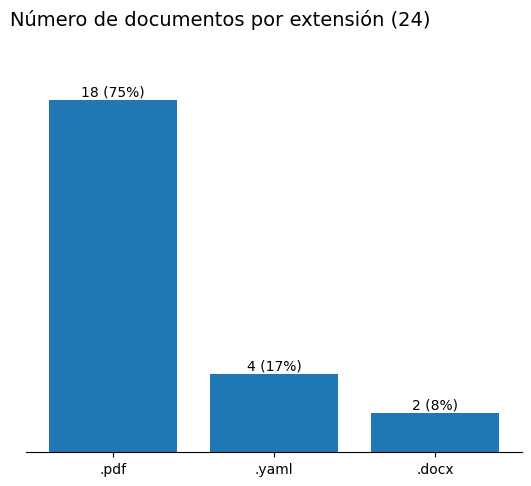

In [7]:
# Genera una grafica con el numero de files por extension
fig, ax = plt.subplots()

x = extensiones_count.keys()
y = extensiones_count.values()
total = sum(y)

ax.bar(x, y)

for i, (count, ext) in enumerate(zip(y, x)):
    ax.text(i, count + 0.1, f"{count} ({count/total:.0%})", ha='center', va='bottom')

# Aesthetics
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.yaxis.set_visible(False)
fig.text(0.1, 1.0, f'Número de documentos por extensión ({total})', ha='left', size=14,)

In [8]:
# Ahora, cuantos files hay por directorio?
subdir_counts = (df_pages
                 .groupby('subdir')
                 ['file'].count()
                 .sort_values(ascending=True)
                 .to_dict()
                )

subdir_counts

{'iso27001': 1,
 'audit-methodology': 4,
 'ciso-assistant-community': 4,
 'audit-examples': 7,
 'sponsor-documents': 8}

Text(0.1, 1.0, 'Número de documentos por subdirectorio (24)')

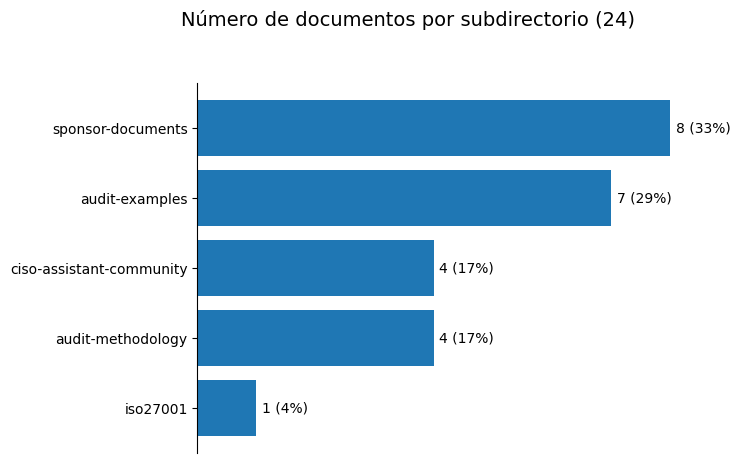

In [9]:
fig, ax = plt.subplots()

x, y = (subdir_counts.keys(), subdir_counts.values())
total = sum(y)
ax.barh(x, y)

for i, (count, subdir) in enumerate(zip(y, x)):
    ax.text(count + 0.1, i, f"{count} ({count/total:.0%})", ha='left', va='center')

# Aesthetics
for spine in ['top', 'right', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_visible(False)
fig.text(0.1, 1.0, f'Número de documentos por subdirectorio ({total})', ha='left', size=14)

## 2. Estadísticas por documento

Para cada archivo del knowledge base se calculará el número de páginas, el conteo de palabras y el número de tokens estimado con el tokenizador `cl100k_base` de OpenAI. Estas métricas permiten anticipar cómo se comportará cada documento durante la etapa de chunking: documentos con un alto número de tokens requerirán más chunks, lo que impacta directamente el tamaño del índice vectorial y los costos de embedding. Identificar outliers (documentos excesivamente largos o cortos) también ayuda a detectar archivos con extracción de texto deficiente, como PDFs escaneados sin OCR.

### 2.1 Conteo de páginas

Se identifican los documentos con un concepto de página definido (PDF y DOCX) y se obtiene el número de páginas de cada uno. Para PDFs se usa `pdfplumber`; para DOCX se aproxima dividiendo el conteo de palabras entre 250 (promedio estándar de palabras por página). Esta métrica permite anticipar qué documentos dominarán el índice vectorial y detectar archivos con extracción deficiente.

Text(0.1, 1.0, 'Distribución del conteo de páginas por documento')

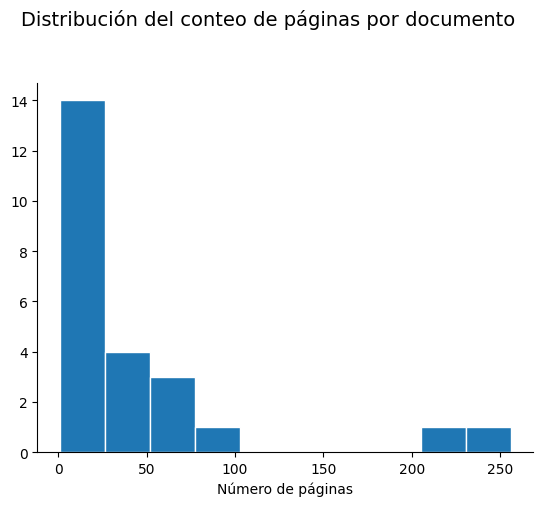

In [10]:
# Crea la figura y el eje
fig, ax = plt.subplots()

# Genera el histograma con 10 bins; edgecolor='white' separa visualmente las barras
ax.hist(df_pages['pages'], bins=10, edgecolor='white')

# Oculta los bordes superiores y derechos para una estética más limpia
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.set_xlabel('Número de páginas')
fig.text(0.1, 1.0, 'Distribución del conteo de páginas por documento', ha='left', size=14)

Text(0.1, 1.0, 'Total de páginas por subdirectorio')

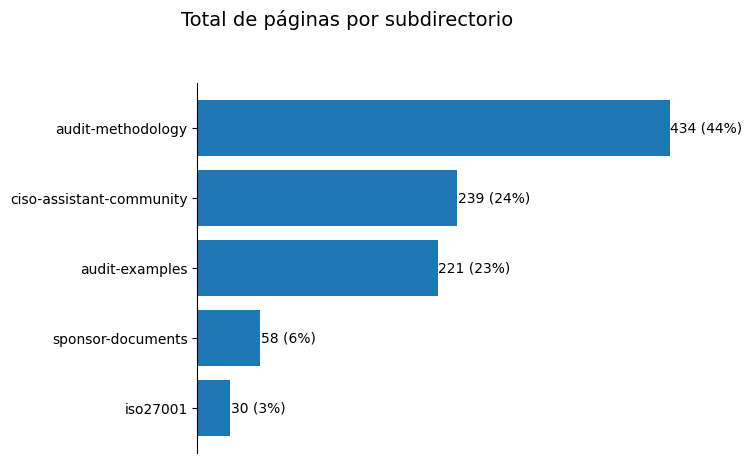

In [11]:
# Agrupa por subdirectorio y suma el total de páginas, ordenado de mayor a menor
pages_by_subdir = df_pages.groupby('subdir')['pages'].sum().sort_values(ascending=True)

# Total de páginas en todo el knowledge base (para calcular porcentajes)
total_pages = pages_by_subdir.sum()

# Crea la figura y el eje
fig, ax = plt.subplots()

# Genera el gráfico de barras horizontal
ax.barh(pages_by_subdir.index.tolist(), pages_by_subdir.values)

# Añade etiquetas con el conteo y el porcentaje a la derecha de cada barra
for i, (count, subdir) in enumerate(zip(pages_by_subdir.values, pages_by_subdir.index)):
    ax.text(count + 0.5, i, f"{count} ({count/total_pages:.0%})", ha='left', va='center')

# Oculta bordes y eje X para una estética más limpia
for spine in ['top', 'right', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_visible(False)

fig.text(0.1, 1.0, 'Total de páginas por subdirectorio', ha='left', size=14)

### 2.2 Conteo de tokens

Los tokens son la unidad mínima que procesa un modelo de lenguaje. A diferencia de las palabras, un token puede ser una sílaba, una palabra completa o un símbolo, dependiendo del vocabulario del modelo. Conocer la distribución de tokens por documento es crítico para el pipeline RAG por tres razones:
1. **Límite de contexto:** Los modelos tienen un máximo de tokens por llamada (p. ej. 128k para Claude). Documentos muy largos deben fragmentarse.
2. **Costo:** Las APIs cobran por token. Conocer el volumen total permite estimar el costo de indexación y consulta.
3. **Calidad del chunking:** Documentos con pocos tokens pueden fusionarse; los de muchos tokens requieren una estrategia de solapamiento cuidadosa.

In [12]:
# Estadísticas generales del conteo de tokens
total_tokens = df_pages['tokens'].sum()
mean_tokens = df_pages['tokens'].mean()
min_tokens = df_pages['tokens'].min()
max_tokens = df_pages['tokens'].max()
std_tokens = df_pages['tokens'].std()

print(f"Total de tokens : {total_tokens:,}")
print(f"Media           : {mean_tokens:,.1f}")
print(f"Mínimo          : {min_tokens:,}")
print(f"Máximo          : {max_tokens:,}")
print(f"Desv. estándar  : {std_tokens:,.1f}")

Total de tokens : 563,869
Media           : 23,494.5
Mínimo          : 269
Máximo          : 202,511
Desv. estándar  : 45,156.8


Text(0.1, 1.0, 'Total de tokens por subdirectorio (563,869)')

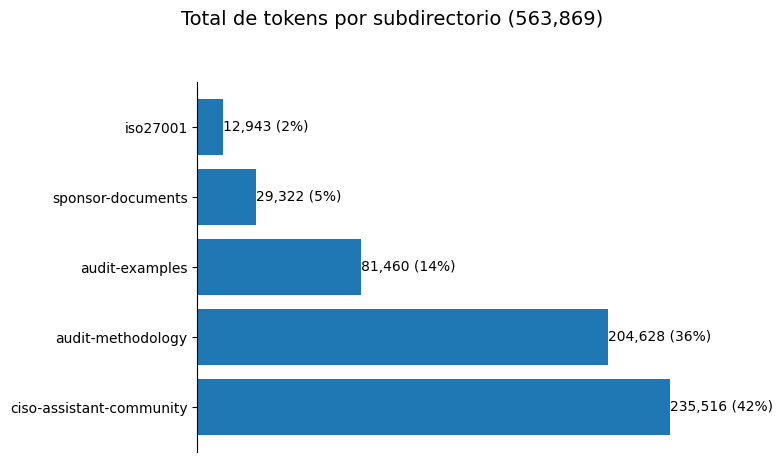

In [13]:
# Tokens por subdirectorio
tokens_by_subdir = df_pages.groupby('subdir')['tokens'].sum().sort_values(ascending=False)
total_tokens = tokens_by_subdir.sum()

fig, ax = plt.subplots()
ax.barh(tokens_by_subdir.index.tolist(), tokens_by_subdir.values)

for i, (subdir, count) in enumerate(zip(tokens_by_subdir.index, tokens_by_subdir.values)):
    ax.text(count + 0.5, i, f"{count:,} ({count/total_tokens:.0%})", ha='left', va='center')

for spine in ['top', 'right', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_visible(False)
fig.text(0.1, 1.0, f'Total de tokens por subdirectorio ({total_tokens:,})', ha='left', size=14)

Text(0.1, 1.0, 'Total de tokens por extensión (563,869)')

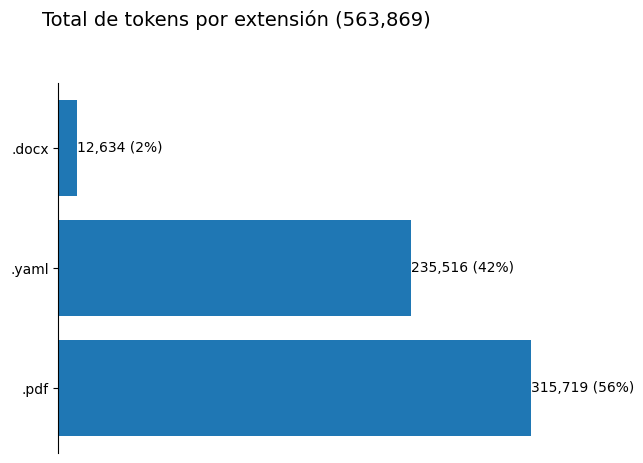

In [14]:
# Tokens por extensión
tokens_by_ext = df_pages.groupby('extension')['tokens'].sum().sort_values(ascending=False)
total_tokens = tokens_by_ext.sum()

fig, ax = plt.subplots()
ax.barh(tokens_by_ext.index.tolist(), tokens_by_ext.values)

for i, (ext, count) in enumerate(zip(tokens_by_ext.index, tokens_by_ext.values)):
    ax.text(count + 0.5, i, f"{count:,} ({count/total_tokens:.0%})", ha='left', va='center')

for spine in ['top', 'right', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_visible(False)
fig.text(0.1, 1.0, f'Total de tokens por extensión ({total_tokens:,})', ha='left', size=14)

## 3. Detección de idioma

La base de conocimiento mezcla documentos en español e inglés. Conocer el idioma de cada archivo es relevante por tres razones:
1. **Embeddings:** Algunos modelos de embeddings tienen mejor desempeño en un solo idioma; documentos en idioma distinto al esperado pueden degradar la calidad de recuperación.
2. **Chunking:** Los tokenizadores y las reglas de separación de oraciones varían por idioma.
3. **Prompts del agente:** El agente necesita saber en qué idioma responder y citar fuentes.

Se toma una muestra aleatoria de 100 palabras por documento para la detección, lo que es suficiente para que `langdetect` identifique el idioma con alta confianza sin procesar el documento completo.

In [15]:
# Detecta el idioma de cada documento usando una muestra de 100 palabras
lang_records = []
for filename, words in words_by_doc.items():
    sample = random.sample(words, min(100, len(words)))
    text_sample = " ".join(sample)
    try:
        language = detect(text_sample)
    except LangDetectException:
        language = "unknown"
    lang_records.append({'file': filename, 'language': language})

df_lang = (pd.DataFrame(lang_records)
           .query('~file.isin(["iso-iec-27001-2013-en-image.pdf"])')
          )

# Une con df_pages para tener subdir, extension y words por archivo
df_lang = df_lang.merge(df_pages[['file', 'subdir', 'extension', 'words']], on='file', how='left')

# Corrección manual: iso27001-2022.yaml es en inglés
df_lang.loc[df_lang['file'] == 'iso27001-2022.yaml', 'language'] = 'en'

df_lang

,file,language,subdir,extension,words
0,06100-FO8-Audit-Report_27001-2022_v4.0.docx,en,audit-examples,.docx,1999
1,2017_iso-iec_27001_isms_precertification_audit...,en,audit-examples,.pdf,13722
2,anonimized-iso-27001-initial-assessment-report...,en,audit-examples,.pdf,9296
3,hcpc-audit-report-2018.pdf,en,audit-examples,.pdf,10175
4,Independent-Press-Standards-Organisation-ISO-2...,en,audit-examples,.pdf,5110
5,redacted-true-iso-27001_audit-report.pdf,en,audit-examples,.pdf,3266
6,Soterion-ISO-27001-Certificate-1.pdf,en,audit-examples,.pdf,11705
7,2.1_requisitos_norma_iso_19011-2011.pdf,es,audit-methodology,.pdf,19668
8,ieeg-resultados-de-auditoria-en-madurez-ti-v1....,es,audit-methodology,.pdf,67767
9,planeacion-de-auditoria-prep-v1.1-2015.pdf,es,audit-methodology,.pdf,5403


Text(0.1, 1.0, 'Distribución de archivos por idioma (24 archivos)')

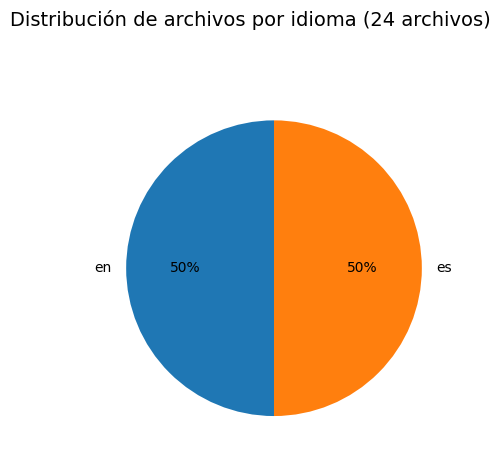

In [16]:
# Pie chart: número de archivos por idioma
files_by_lang = df_lang['language'].value_counts()

fig, ax = plt.subplots()
ax.pie(files_by_lang.values, labels=files_by_lang.index, autopct='%1.0f%%', startangle=90)
fig.text(0.1, 1.0, f'Distribución de archivos por idioma ({len(df_lang)} archivos)', ha='left', size=14)

Text(0.1, 1.0, 'Distribución de palabras por idioma (257,037 palabras)')

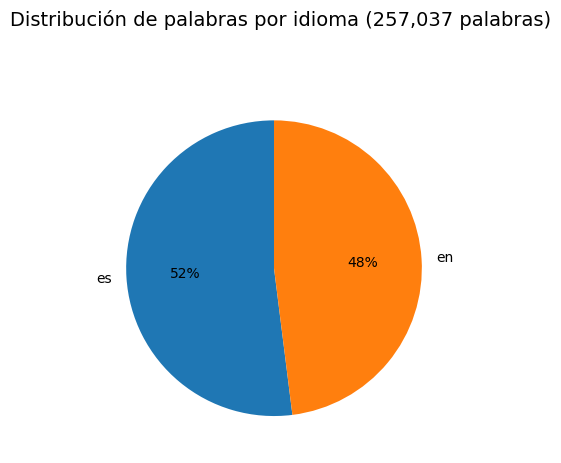

In [17]:
# Pie chart: distribución de palabras por idioma
# El idioma detectado por archivo se aplica a todas sus palabras
words_by_lang = df_lang.groupby('language')['words'].sum().sort_values(ascending=False)
total_words = words_by_lang.sum()

fig, ax = plt.subplots()
ax.pie(words_by_lang.values, labels=words_by_lang.index, autopct='%1.0f%%', startangle=90)
fig.text(0.1, 1.0, f'Distribución de palabras por idioma ({total_words:,} palabras)', ha='left', size=14)

Text(0.1, 1.0, 'Distribución de idiomas por extensión (% palabras)')

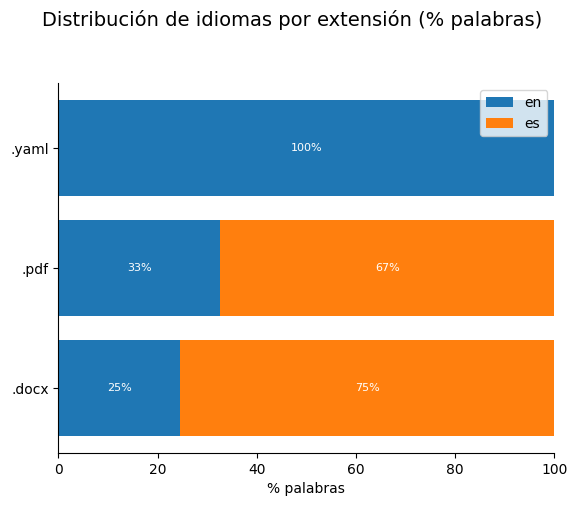

In [18]:
# Stacked bar: % de palabras por idioma para cada extensión
pivot_ext = df_lang.groupby(['extension', 'language'])['words'].sum().unstack(fill_value=0)
pivot_ext_pct = pivot_ext.div(pivot_ext.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots()
left = np.zeros(len(pivot_ext_pct))
colors = plt.cm.tab10.colors

for i, lang in enumerate(pivot_ext_pct.columns):
    ax.barh(pivot_ext_pct.index, pivot_ext_pct[lang], left=left, label=lang, color=colors[i])
    for j, val in enumerate(pivot_ext_pct[lang]):
        if val > 5:
            ax.text(left[j] + val / 2, j, f'{val:.0f}%', ha='center', va='center', fontsize=8, color='white')
    left += pivot_ext_pct[lang].values

ax.set_xlabel('% palabras')
ax.legend(loc='upper right')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
fig.text(0.1, 1.0, 'Distribución de idiomas por extensión (% palabras)', ha='left', size=14)

Text(0.1, 1.0, 'Distribución de idiomas por subdirectorio (% palabras)')

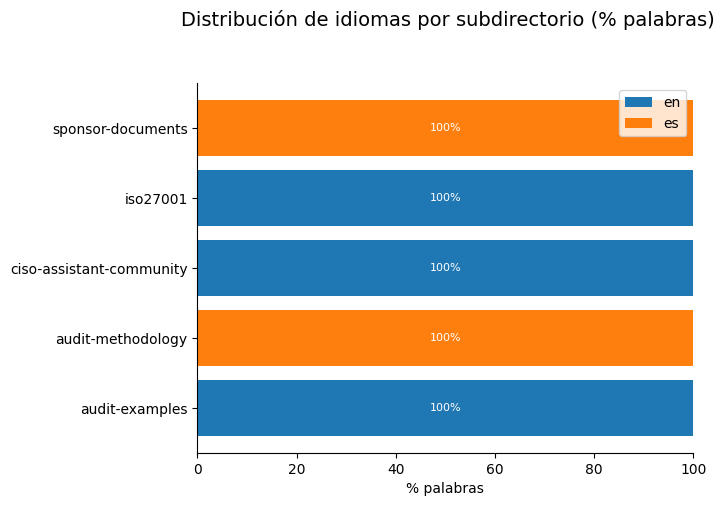

In [19]:
# Stacked bar: % de palabras por idioma para cada subdirectorio
pivot_sub = df_lang.groupby(['subdir', 'language'])['words'].sum().unstack(fill_value=0)
pivot_sub_pct = pivot_sub.div(pivot_sub.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots()
left = np.zeros(len(pivot_sub_pct))
colors = plt.cm.tab10.colors

for i, lang in enumerate(pivot_sub_pct.columns):
    ax.barh(pivot_sub_pct.index, pivot_sub_pct[lang], left=left, label=lang, color=colors[i])
    for j, val in enumerate(pivot_sub_pct[lang]):
        if val > 5:
            ax.text(left[j] + val / 2, j, f'{val:.0f}%', ha='center', va='center', fontsize=8, color='white')
    left += pivot_sub_pct[lang].values

ax.set_xlabel('% palabras')
ax.legend(loc='upper right')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
fig.text(0.1, 1.0, 'Distribución de idiomas por subdirectorio (% palabras)', ha='left', size=14)

## 4. Nubes de palabras

Las nubes de palabras (*word clouds*) permiten visualizar de forma intuitiva los términos más frecuentes en el corpus. El tamaño de cada palabra es proporcional a su frecuencia: cuanto mayor aparece, más veces se menciona en los documentos.

Se generan dos visualizaciones:
- Una nube consolidada con todos los documentos del knowledge base.
- Una nube individual por subdirectorio, para comparar el vocabulario de cada fuente.

Text(0.1, 1.0, 'Nube de palabras — Knowledge Base completo')

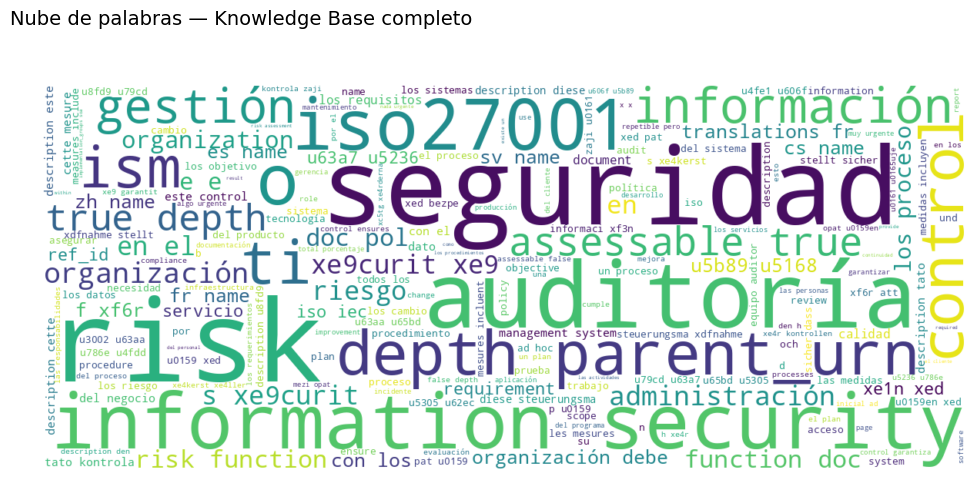

In [20]:
# Combina todas las palabras del knowledge base en un solo texto
all_words = [word for words in words_by_doc.values() for word in words]
text_all = " ".join(all_words)
stopwords = list(STOPWORDS) + ['de', 'la', 'y', 'urn', 'intuitem', 'item', 'req_node', 'para', 'que', 'lo']

wc_all = WordCloud(width=1200, height=500, background_color='white',
                   max_words=200,
                   stopwords=stopwords
                  ).generate(text_all)

fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(wc_all, interpolation='bilinear')
ax.axis('off')
fig.text(0.1, 1.0, 'Nube de palabras — Knowledge Base completo', ha='left', size=14)

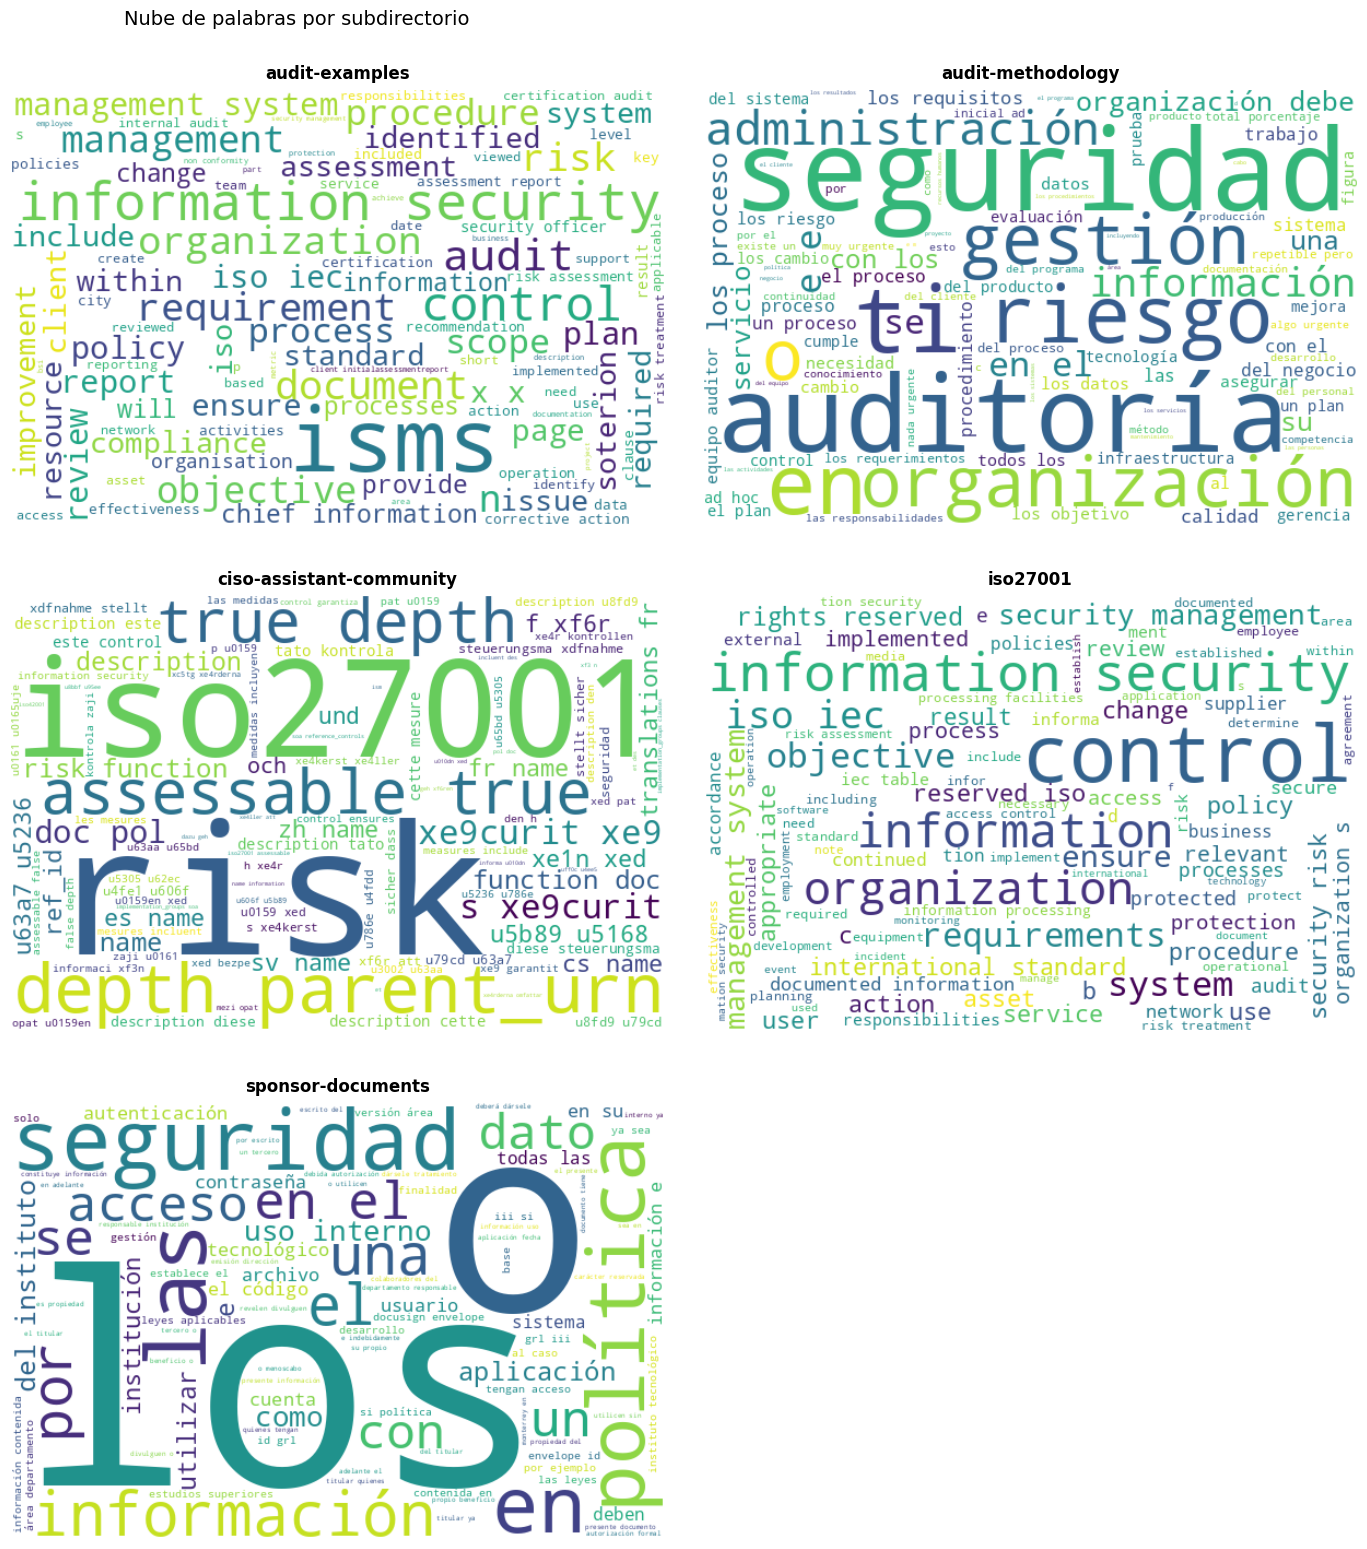

In [21]:
# Agrupa palabras por subdirectorio usando el mapeo de df_pages
words_by_subdir = {}
for _, row in df_pages.iterrows():
    subdir = row['subdir']
    filename = row['file']
    if filename in words_by_doc:
        words_by_subdir.setdefault(subdir, []).extend(words_by_doc[filename])

subdirs = sorted(words_by_subdir.keys())
ncols = 2
nrows = -(-len(subdirs) // ncols)  # ceiling division

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 5))
axes = axes.flatten()

for i, subdir in enumerate(subdirs):
    text = " ".join(words_by_subdir[subdir])
    wc = WordCloud(width=600, height=400, background_color='white',
                   max_words=100,
                   stopwords=stopwords
                  ).generate(text)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(subdir, fontsize=12, pad=8, fontweight='bold')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.text(0.1, 1.02, 'Nube de palabras por subdirectorio', ha='left', size=14)
plt.tight_layout(h_pad=4)